In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%pip install ultralytics gradio

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 471.0 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 10.3 MB/s eta 0:00:00


In [ ]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive/beealarmed/yolo_v2")
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def count_images(folder):
    return sum(
        1 for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in EXTS
    )

train = count_images(BASE / "images" / "train")
val = count_images(BASE / "images" / "val")
total = train + val

print("=== SPLIT DE yolo_v2 ===")
print(f"Train: {train:,} imágenes ({train / total * 100:.2f}%)")
print(f"Val:   {val:,} imágenes ({val / total * 100:.2f}%)")
print(f"Total: {total:,} imágenes")
print(f"Ratio train:val = {train}:{val}")

=== SPLIT DE yolo_v2 ===
Train: 2,073 imágenes (93.55%)
Val:   143 imágenes (6.45%)
Total: 2,216 imágenes
Ratio train:val = 2073:143


In [ ]:
from pathlib import Path
from ultralytics import YOLO
import torch

DATA = Path("/content/drive/MyDrive/beealarmed/yolo_v2/data.yaml")

if not DATA.exists():
    raise FileNotFoundError(f"No existe: {DATA}")

print("GPU disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

model = YOLO("yolo11n.pt")

results = model.train(
    data=str(DATA),
    epochs=100,
    imgsz=640,
    batch=16,
    patience=20,
    weight_decay=0.0005,
    degrees=5.0,
    fliplr=0.5,
    close_mosaic=10,
    project="/content/drive/MyDrive/beealarmed/runs",
    name="yolo11n_v2",
    exist_ok=False,
    seed=42,
    plots=True,
    save=True
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU disponible: True
GPU: Tesla T4
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/beealarmed/yolo_v2/data.yaml, degrees=5.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, 

In [ ]:
from pathlib import Path
from ultralytics import YOLO
import torch

BASE = Path("/content/drive/MyDrive/beealarmed")
RUN = BASE / "runs" / "yolo11n_v2"
BEST = RUN / "weights" / "best.pt"
DATA = BASE / "yolo_v2" / "data.yaml"

if not BEST.exists():
    raise FileNotFoundError(f"No se encontró el mejor modelo: {BEST}")

model = YOLO(str(BEST))

metrics = model.val(
    data=str(DATA),
    split="val",
    imgsz=640,
    batch=16,
    plots=True,
    project=str(BASE / "evaluation"),
    name="yolo11n_v2_val",
    exist_ok=True
)

print("\n=== MÉTRICAS YOLO11n v2 ===")
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Precisión por clase:", metrics.box.p)
print("Recall por clase:", metrics.box.r)
print("mAP50 por clase:", metrics.box.maps)
print("Clases:", model.names)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 14.6±4.8 MB/s, size: 13.7 KB)
val: Scanning /content/drive/MyDrive/beealarmed/yolo_v2/labels/val.cache... 143 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 143/143 31.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 3.6it/s 2.5s
                   all        143        183      0.984      0.988      0.985      0.752
                   bee         44         44      0.995          1      0.995      0.841
                varroa         39         40      0.999      0.975      0.975      0.636
                  wasp         99         99      0.957       0.99      0.985       0.78
Speed: 2.1ms preprocess, 4.2ms inference, 0.0ms loss, 3.2ms postprocess per image
Results saved to /content/drive/MyD

In [ ]:
from pathlib import Path
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/beealarmed")
BEST = BASE / "runs" / "yolo11n_v2" / "weights" / "best.pt"

model = YOLO(str(BEST))
metrics = model.val(
    data=str(BASE / "yolo_v2" / "data.yaml"),
    split="val",
    imgsz=640,
    batch=16,
    plots=True,
    project=str(BASE / "evaluation"),
    name="yolo11n_v2_val",
    exist_ok=True
)

print("\n=== AP POR CLASE CORREGIDO ===")
for i, name in model.names.items():
    if i in metrics.box.ap_class_index:
        idx = list(metrics.box.ap_class_index).index(i)
        ap50 = metrics.box.ap50[idx]  # Acceso directo al AP50 real
        ap5095 = metrics.box.ap[idx]  # El array .ap representa AP50-95 por clase
        print(f"{name}: AP50={ap50:.4f}, AP50-95={ap5095:.4f}")

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.3 ms, read: 12.2±5.0 MB/s, size: 13.7 KB)
val: Scanning /content/drive/MyDrive/beealarmed/yolo_v2/labels/val.cache... 143 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 143/143 35.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 3.5it/s 2.6s
                   all        143        183      0.984      0.988      0.985      0.752
                   bee         44         44      0.995          1      0.995      0.841
                varroa         39         40      0.999      0.975      0.975      0.636
                  wasp         99         99      0.957       0.99      0.985       0.78
Speed: 2.0ms preprocess, 3.3ms inference, 0.0ms loss, 3.4ms postprocess per image
Results saved to /content/drive/MyD

confusion_matrix.png


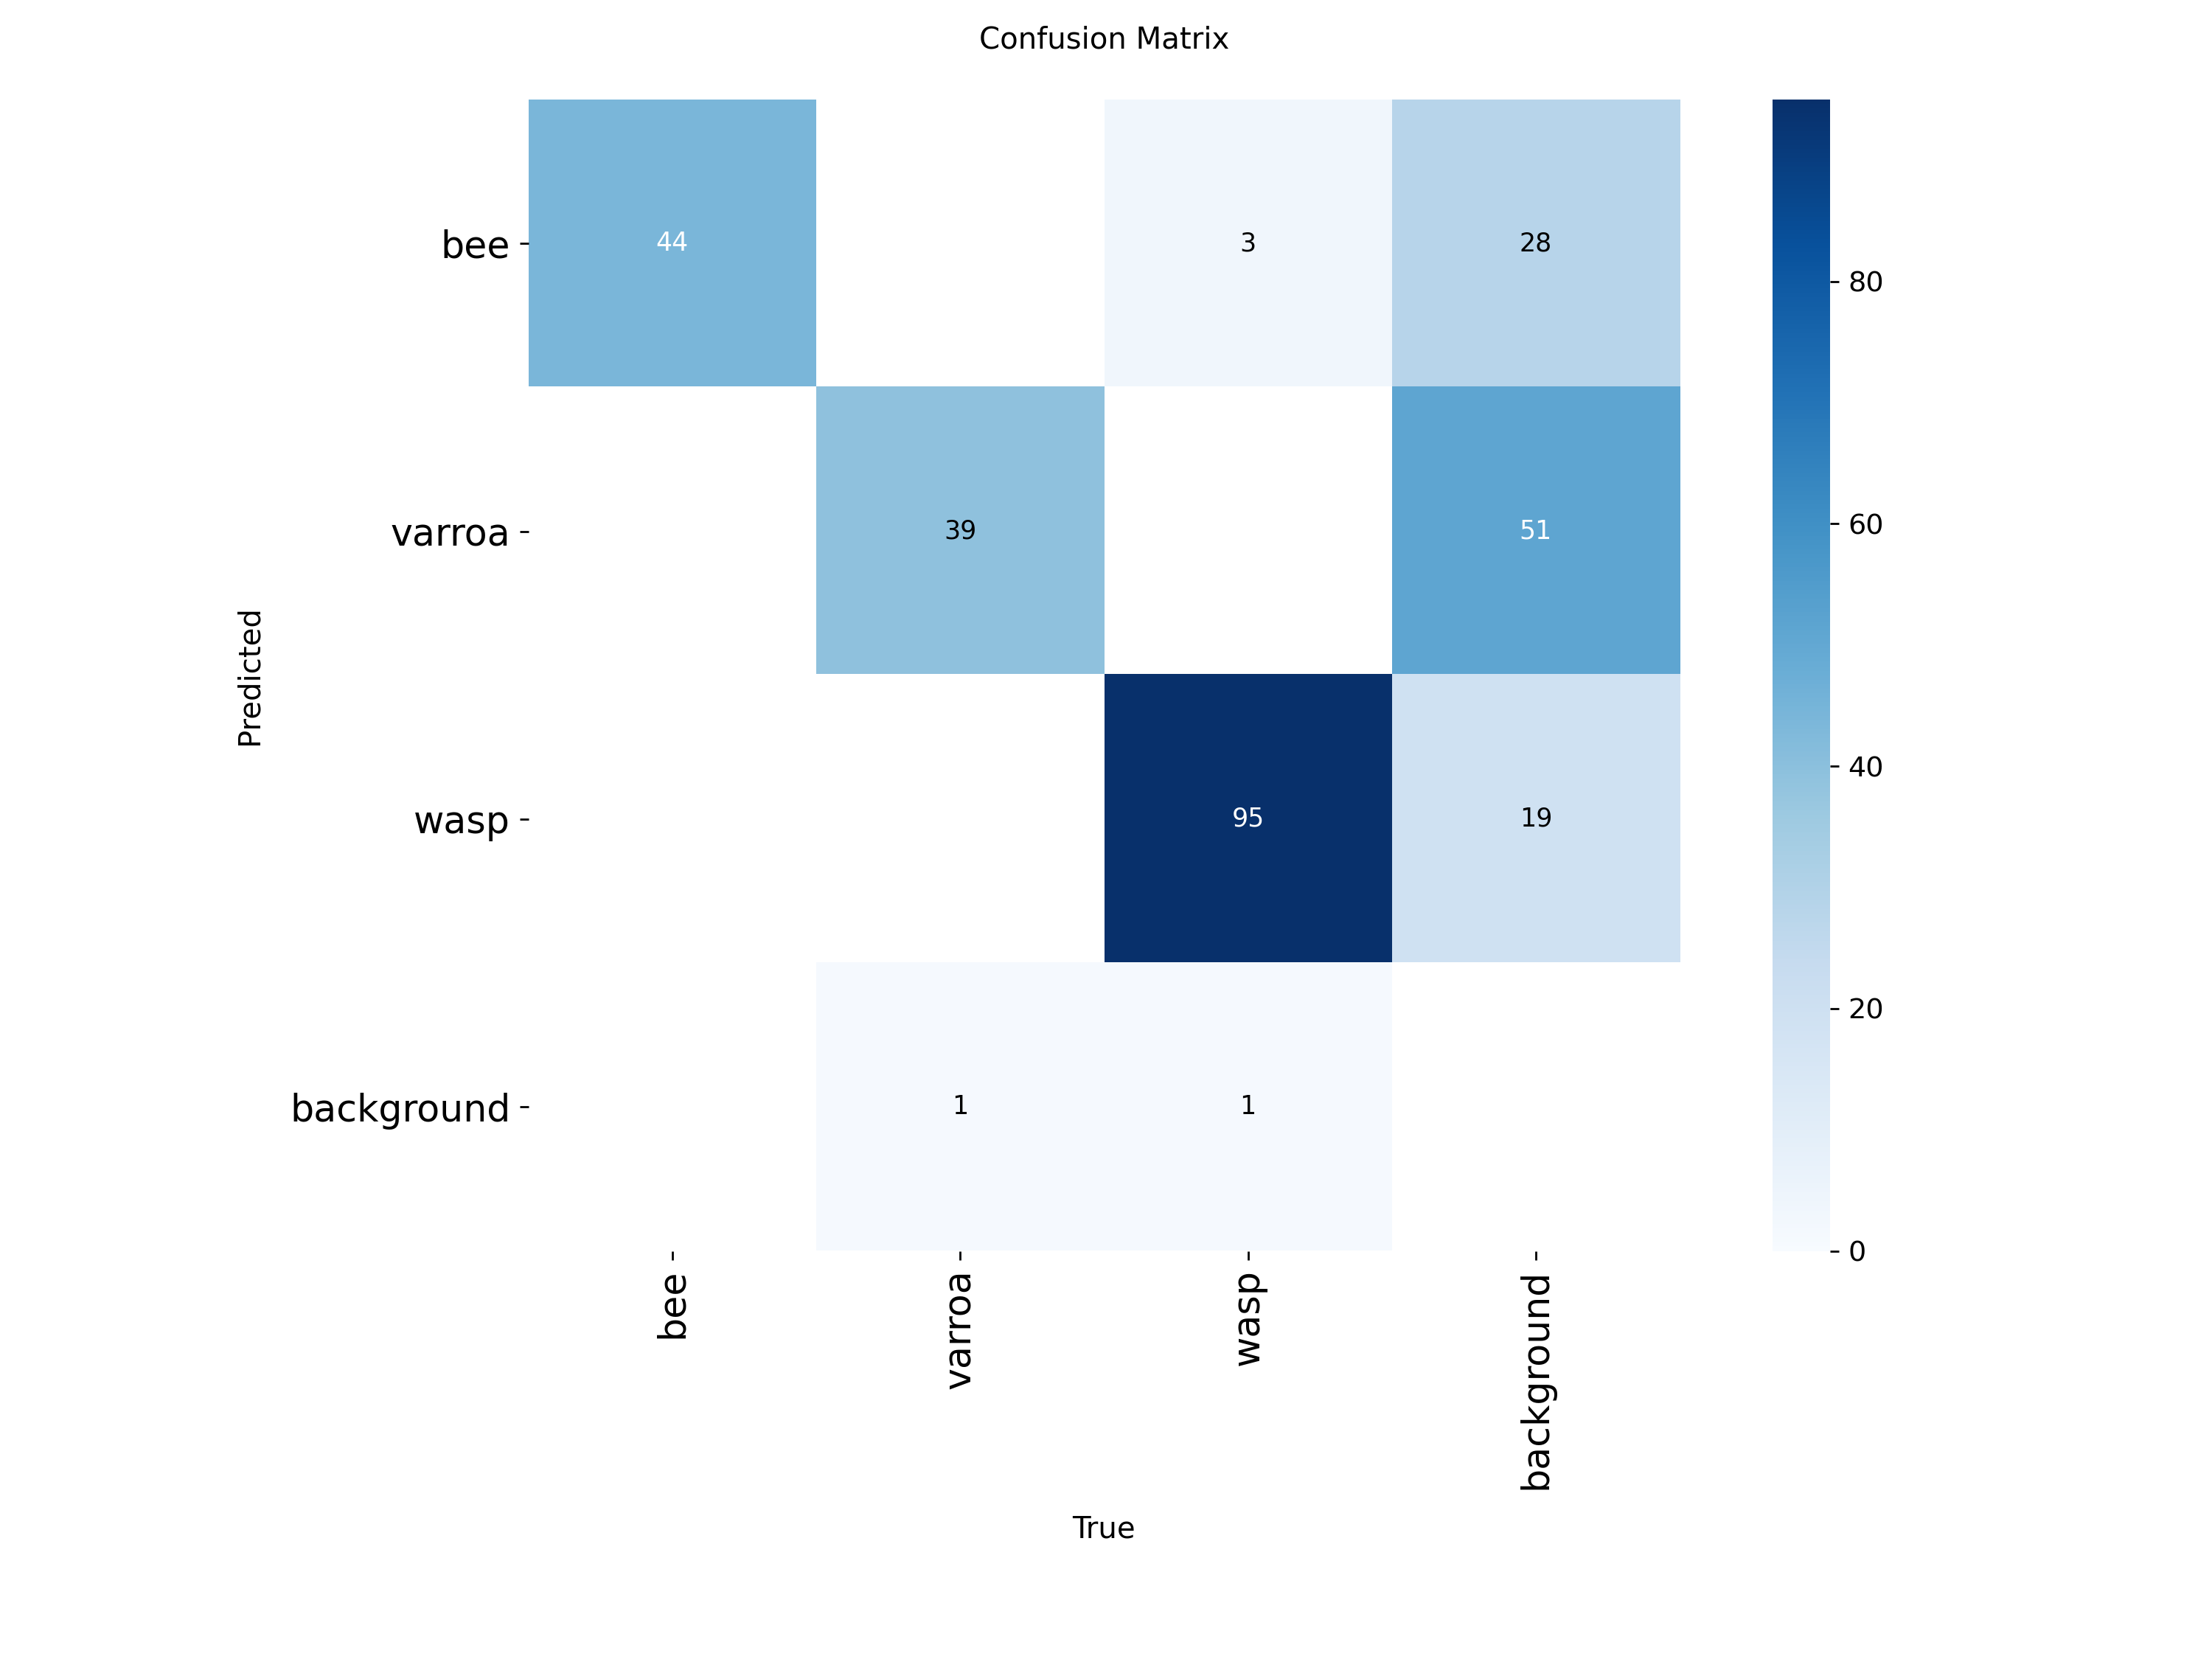

In [ ]:
from pathlib import Path
from IPython.display import display, Image

RESULTS = Path(
    "/content/drive/MyDrive/beealarmed/evaluation/yolo11n_v2_val"
)

for name in [
    "confusion_matrix.png",
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png",
    "results.png",
]:
    path = RESULTS / name
    if path.exists():
        print(name)
        display(Image(filename=str(path)))

PREDICTION

In [ ]:
import os
path_best = '/content/drive/MyDrive/beealarmed/runs/yolo11n_v2/weights/best.pt'
if os.path.exists(path_best):
    modelo = YOLO(path_best)
    print("✅ Modelo YOLO11n cargado correctamente")
else:
    print("❌ No se encontró el modelo. Verifica la ruta.")

✅ Modelo YOLO11n cargado correctamente


In [ ]:
import gradio as gr
from PIL import Image
import numpy as np

def detectar_objetos(imagen, confianza):
    if imagen is None:
        return None, "Primero debes cargar una imagen."

    resultados = modelo.predict(
        source=imagen,
        conf=confianza,
        verbose=False
    )

    # Imagen con cajas delimitadoras
    imagen_resultado = resultados[0].plot()
    imagen_resultado = imagen_resultado[:, :, ::-1]

    # Información de las detecciones
    cajas = resultados[0].boxes

    if len(cajas) == 0:
        resumen = "No se detectaron objetos."
    else:
        lineas = []
        for caja in cajas:
            clase_id = int(caja.cls[0].item())
            nombre = resultados[0].names[clase_id]
            confianza_objeto = float(caja.conf[0].item())

            lineas.append(
                f"{nombre}: {confianza_objeto:.1%} de confianza"
            )

        resumen = (
            f"Total de objetos detectados: {len(cajas)}\n\n"
            + "\n".join(lineas)
        )

    return Image.fromarray(imagen_resultado), resumen


with gr.Blocks(title="Detector YOLO11n") as interfaz:
    gr.Markdown("# Detector de objetos con YOLO11n")
    gr.Markdown("Carga una imagen y pulsa el botón para analizarla.")

    imagen_entrada = gr.Image(
        type="pil",
        label="Imagen de entrada"
    )

    confianza = gr.Slider(
        minimum=0.1,
        maximum=0.9,
        value=0.25,
        step=0.05,
        label="Confianza mínima"
    )

    boton = gr.Button("Detectar objetos")

    imagen_salida = gr.Image(
        type="pil",
        label="Imagen con detecciones"
    )

    texto_resultados = gr.Textbox(
        label="Resultados",
        lines=8
    )

    boton.click(
        fn=detectar_objetos,
        inputs=[imagen_entrada, confianza],
        outputs=[imagen_salida, texto_resultados]
    )

interfaz.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9723ad49a426dcaba1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [3]:
from pathlib import Path
from ultralytics import YOLO
import random
import shutil

BASE = Path("/content/drive/MyDrive/beealarmed")
DATASET = BASE / "yolo_v2"
MODEL_PATH = BASE / "runs/yolo11n_v2/weights/best.pt"
OUTPUT = BASE / "diagnostics/yolo11n_v2"

IMAGES = DATASET / "images/val"
LABELS = DATASET / "labels/val"

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"No se encontró el modelo: {MODEL_PATH}")

if not IMAGES.exists() or not LABELS.exists():
    raise FileNotFoundError("No se encontraron las carpetas de validación.")

# Limpiar únicamente el directorio de diagnóstico anterior.
if OUTPUT.exists():
    shutil.rmtree(OUTPUT)

OUTPUT.mkdir(parents=True)
GT_DIR = OUTPUT / "ground_truth"
PRED_DIR = OUTPUT / "predictions"
COMPARE_DIR = OUTPUT / "comparison"

for folder in [GT_DIR, PRED_DIR, COMPARE_DIR]:
    folder.mkdir(parents=True)

model = YOLO(str(MODEL_PATH))

image_paths = sorted(
    p for p in IMAGES.iterdir()
    if p.is_file() and p.suffix.lower() in
    {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

# Confianza baja para facilitar la inspección de falsos positivos.
CONF = 0.10
IOU = 0.50
IMGSZ = 640

random.seed(42)

print("Imágenes de validación:", len(image_paths))
print("Generando visualizaciones...")

for i, image_path in enumerate(image_paths, start=1):
    label_path = LABELS / f"{image_path.stem}.txt"

    if not label_path.exists():
        print("Etiqueta faltante:", image_path.name)
        continue

    # Predicción del modelo.
    result = model.predict(
        source=str(image_path),
        conf=CONF,
        iou=IOU,
        imgsz=IMGSZ,
        verbose=False
    )[0]

    # Imagen con las predicciones.
    pred_image = result.plot()
    import cv2
    cv2.imwrite(str(PRED_DIR / f"{image_path.stem}.jpg"), pred_image)

    # Imagen con las cajas reales, leídas de las etiquetas YOLO.
    image = cv2.imread(str(image_path))
    h, w = image.shape[:2]

    for line in label_path.read_text(encoding="utf-8").splitlines():
        parts = line.split()
        if len(parts) != 5:
            continue

        cls = int(parts[0])
        x, y, bw, bh = map(float, parts[1:])

        x1 = int((x - bw / 2) * w)
        y1 = int((y - bh / 2) * h)
        x2 = int((x + bw / 2) * w)
        y2 = int((y + bh / 2) * h)

        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(
            image,
            model.names[cls],
            (max(0, x1), max(15, y1 - 5)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 0),
            2
        )

    cv2.imwrite(str(GT_DIR / f"{image_path.stem}.jpg"), image)

    # Comparación lado a lado: izquierda = real, derecha = predicción.
    gt = cv2.imread(str(GT_DIR / f"{image_path.stem}.jpg"))
    pred = cv2.imread(str(PRED_DIR / f"{image_path.stem}.jpg"))

    if gt.shape[:2] != pred.shape[:2]:
        pred = cv2.resize(pred, (gt.shape[1], gt.shape[0]))

    comparison = cv2.hconcat([gt, pred])
    cv2.imwrite(str(COMPARE_DIR / f"{image_path.stem}.jpg"), comparison)

    if i % 25 == 0 or i == len(image_paths):
        print(f"Procesadas: {i}/{len(image_paths)}")

print("\nListo.")
print("Comparaciones:", COMPARE_DIR)
print("Verde = cajas reales; derecha = predicciones del modelo.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Imágenes de validación: 143
Generando visualizaciones...
Procesadas: 25/143
Procesadas: 50/143
Procesadas: 75/143
Procesadas: 100/143
Procesadas: 125/143
Procesadas: 143/143

Listo.
Comparaciones: /content/drive/MyDrive/beealarmed/diagnostics/yolo11n_v2/comparison
Verde = cajas reales; derecha = predicciones del modelo.
